# Jeux globaux — la sélection d'équilibre par le bruit privé

*Carnet 11f de la série GameTheory — prolonge 11 (jeux bayésiens) et 10 (induction en avant).*

**Navigation** : [<< 11-BayesianGames](GameTheory-11-BayesianGames-Python.ipynb) | [Index](README.md)

Un jeu de **coordination** possède, à information complète, plusieurs équilibres : rien dans les payoffs ne désigne celui qui sera joué. Les **jeux globaux** (Carlsson et van Damme, 1993) lèvent cette indétermination en perturbant l'information : l'état de l'économie n'est pas observé exactement, mais à travers un **signal privé bruité**. Deux résultats en découlent, et ce carnet les mesure :

1. l'équilibre devient **unique**, et prend la forme d'une **stratégie de coupure** ;
2. quand le bruit s'éteint, cette coupure converge vers l'équilibre **risque-dominant** au sens de Harsanyi et Selten — et non vers l'équilibre Pareto-dominant, avec lequel il entre en conflit sur une moitié de la bande de multiplicité.

C'est une sélection obtenue par la **croyance**, non par le temps. L'induction en avant du carnet 10 opère l'autre sélection, le long de l'arbre : là, chaque nœud est visité et la crédibilité tranche ; ici, tout est simultané et seule la finesse du signal tranche.

**Plan.** §1 le jeu et sa multiplicité · §2 la perturbation · §3 la coupure unique · §4 ce que la limite sélectionne, mesuré · §5 le raccourci qui ne marche pas · §6 exercices.

## 1. Le jeu — une complémentarité stratégique

Deux joueurs (`i = 1, 2`) choisissent **simultanément** d'**investir** (`I`) ou de s'**abstenir** (`N`). L'état `θ` est le rendement fondamental de l'investissement. Investir coûte `c`, rapporte `θ`, et procure en plus un bonus `γ` **si l'autre investit aussi** :

$$
u_i(I, I) = \theta - c + \gamma, \qquad u_i(I, N) = \theta - c, \qquad u_i(N, \cdot) = 0
$$

Le terme `γ` est la **complémentarité stratégique** : investir vaut davantage quand l'autre investit. C'est lui, et lui seul, qui crée la multiplicité — sans lui, chacun décide seul de son côté, l'investissement est dominé ou dominant selon `θ`, et il n'y a rien à sélectionner.

À information complète (`θ` connu de tous), on vérifie chaque équilibre par **déviation** : `(I, I)` tient si dévier vers `N` ne paie pas, c'est-à-dire si `u(I, I) >= u(N, I) = 0` ; `(N, N)` tient si `u(N, N) = 0 >= u(I, N)`.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

np.random.seed(21932)

MU = 0.8        # moyenne de l'etat theta
SIGMA_T = 0.5   # dispersion de l'etat
C = 1.0         # cout d'investir
GAMMA = 0.6     # complementarite : bonus si l'autre investit aussi


def payoff(action, autre, theta, c=C, gamma=GAMMA):
    """Payoff du joueur i : investir, ou s'abstenir (payoff nul)."""
    if action == "I":
        return theta - c + gamma * (1.0 if autre == "I" else 0.0)
    return 0.0


print(f"mu = {MU}   sigma_theta = {SIGMA_T}   c = {C}   gamma = {GAMMA}")
print(f"bande de multiplicite attendue (c - gamma, c) = ({C - GAMMA:.2f}, {C:.2f})")
print()
print(f"{'theta':>7} {'u(I,I)':>8} {'u(I,N)':>8} {'(I,I) EN':>9} {'(N,N) EN':>9}  regime")
for theta in [0.2, 0.4, 0.6, 0.8, 1.0, 1.3]:
    u_ii = payoff("I", "I", theta)
    u_in = payoff("I", "N", theta)
    eq_ii = u_ii >= 0.0          # devier vers N rapporte 0
    eq_nn = 0.0 >= u_in          # devier vers I rapporte u(I,N)
    if eq_ii and eq_nn:
        regime = "deux equilibres"
    elif eq_ii:
        regime = "(I,I) unique"
    else:
        regime = "(N,N) unique"
    print(f"{theta:7.2f} {u_ii:8.2f} {u_in:8.2f} {str(eq_ii):>9} {str(eq_nn):>9}  {regime}")

mu = 0.8   sigma_theta = 0.5   c = 1.0   gamma = 0.6
bande de multiplicite attendue (c - gamma, c) = (0.40, 1.00)

  theta   u(I,I)   u(I,N)  (I,I) EN  (N,N) EN  regime
   0.20    -0.20    -0.80     False      True  (N,N) unique
   0.40     0.00    -0.60      True      True  deux equilibres
   0.60     0.20    -0.40      True      True  deux equilibres
   0.80     0.40    -0.20      True      True  deux equilibres
   1.00     0.60     0.00      True      True  deux equilibres
   1.30     0.90     0.30      True     False  (I,I) unique


### Lecture du résultat

Trois régimes, séparés par deux seuils :

| `θ` | équilibres | pourquoi |
|---|---|---|
| `θ < c - γ` | `(N, N)` seul | investir perd même si l'autre investit (`u(I, I) < 0`) : `I` est **dominée** |
| `c - γ ≤ θ ≤ c` | **`(I, I)` et `(N, N)`** | chacun veut investir si l'autre investit, et s'abstenir sinon : **deux** équilibres |
| `θ > c` | `(I, I)` seul | investir gagne même si l'autre s'abstient (`u(I, N) > 0`) : `I` est **dominante** |

La bande du milieu est le problème. Sa largeur vaut exactement `γ = 0.60`, et à l'intérieur la théorie est muette : rien, dans les payoffs, ne hiérarchise `(I, I)` et `(N, N)`. Aux deux bornes un équilibre devient faible — `(I, I)` en `θ = c - γ`, `(N, N)` en `θ = c` — ce qui est la signature d'un changement de régime et non d'une indétermination.

Toute la question des jeux globaux tient en une phrase : **que devient cette bande quand les joueurs cessent de connaître `θ` exactement ?**

## 2. La perturbation — un état commun, des signaux privés

`θ` n'est plus connu : c'est un tirage, et **chaque joueur en reçoit un signal bruité** :

$$
\theta \sim \mathcal{N}(\mu, \sigma_\theta^2), \qquad x_i = \theta + \sigma_\varepsilon \, \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, 1) \ \text{i.i.d.}
$$

Le bruit est **privé** : il est indépendant d'un joueur à l'autre. Chacun sait que l'autre détient *un* signal, mais pas lequel. C'est précisément cet angle mort qui fait le travail de sélection.

Vu son signal, le joueur met à jour sa croyance sur `θ` — une moyenne pondérée de l'a priori et du signal :

$$
\lambda = \frac{\sigma_\theta^2}{\sigma_\theta^2 + \sigma_\varepsilon^2}, \qquad
\mathbb{E}[\theta \mid x_i] = \mu + \lambda (x_i - \mu), \qquad
\mathrm{Var}(\theta \mid x_i) = \frac{\sigma_\theta^2 \sigma_\varepsilon^2}{\sigma_\theta^2 + \sigma_\varepsilon^2}
$$

`λ` est la **précision relative** du signal : `λ → 1` quand le bruit s'éteint, `λ → 0` quand il noie l'information.

In [2]:
def coefficients(sigma_eps):
    """Poids du signal (lambda) et variance conditionnelle de theta sachant x_i."""
    st2 = SIGMA_T ** 2
    se2 = sigma_eps ** 2
    lam = st2 / (st2 + se2)
    v_cond = st2 * se2 / (st2 + se2)
    return lam, v_cond


def esperance_etat(x, sigma_eps):
    """E[theta | x_i = x]."""
    lam, _ = coefficients(sigma_eps)
    return MU + lam * (x - MU)


print(f"{'sigma_eps':>10} {'lambda':>9} {'Var(theta|x)':>14} {'sqrt(Var)':>11}")
for se in [1.0, 0.5, 0.3, 0.1, 0.02, 0.001]:
    lam, v_cond = coefficients(se)
    print(f"{se:10.3f} {lam:9.6f} {v_cond:14.6f} {math.sqrt(v_cond):11.6f}")

# controle Monte-Carlo : la formule de mise a jour est-elle la bonne ?
rng = np.random.default_rng(21932)
se_mc = 0.3
theta_mc = rng.normal(MU, SIGMA_T, 400_000)
x_mc = theta_mc + se_mc * rng.normal(0.0, 1.0, 400_000)
proche = np.abs(x_mc - 1.0) < 0.02
print()
print(f"controle a x = 1.0, sigma_eps = {se_mc} :")
print(f"  Monte-Carlo {theta_mc[proche].mean():.5f}  ({int(proche.sum())} tirages autour de x)")
print(f"  formule     {esperance_etat(1.0, se_mc):.5f}")

 sigma_eps    lambda   Var(theta|x)   sqrt(Var)
     1.000  0.200000       0.200000    0.447214
     0.500  0.500000       0.125000    0.353553
     0.300  0.735294       0.066176    0.257248
     0.100  0.961538       0.009615    0.098058
     0.020  0.998403       0.000399    0.019984
     0.001  0.999996       0.000001    0.001000

controle a x = 1.0, sigma_eps = 0.3 :
  Monte-Carlo 0.94337  (10494 tirages autour de x)
  formule     0.94706


### Lecture du résultat

Deux progressions se lisent ensemble. Quand le bruit passe de `1.0` à `0.001`, le poids `λ` du signal monte de `0.200` à `0.999996` et la variance conditionnelle s'effondre de `0.200` à `1e-06` : le joueur cesse d'être incertain. À l'autre bout, `λ = 0.2` dit qu'un signal deux fois plus dispersé que l'état lui-même n'apporte qu'un cinquième de l'information — le cas du joueur qui « ne sait presque rien ».

Le contrôle Monte-Carlo valide la formule de mise à jour. En simulant 400 000 couples `(θ, x)` et en ne gardant que ceux dont le signal tombe à `± 0.02` de `x = 1.0`, la moyenne empirique de `θ` vaut `0.94337`, contre `0.94706` pour `E[θ | x] = μ + λ(x - μ)`. L'écart de `0.0037` est de l'ordre de l'erreur d'échantillonnage de cette moyenne : `0.257 / √10494 ≈ 0.0025`, pour un écart-type conditionnel de `0.257` et 10 494 tirages retenus. La formule est donc la bonne, et c'est elle qui porte toute l'équation d'indifférence du paragraphe suivant.

## 3. L'équilibre à coupure unique

On cherche un équilibre **symétrique en stratégie de coupure** : chaque joueur investit si et seulement si son signal dépasse un seuil `c*`. Un tel équilibre tient dans une seule équation — l'indifférence **au seuil**.

Au signal `c*`, investir et s'abstenir doivent rapporter la même chose :

$$
\underbrace{\mathbb{E}[\theta \mid c^*]}_{\text{gain si l'autre investit}} - c + \gamma \underbrace{\mathbb{P}(x_j \geq c^* \mid x_i = c^*)}_{p} = 0
$$

Reste à calculer `p`. Sachant `x_i`, le signal de l'autre est normal, centré sur la **même** espérance `E[θ | x_i]`, avec la variance `Var(θ | x_i) + σ_ε²` — l'incertitude sur l'état **plus** le bruit propre de l'autre :

$$
p = \Phi\!\left( \frac{\mathbb{E}[\theta \mid c^*] - c^*}{\sqrt{\mathrm{Var}(\theta \mid c^*) + \sigma_\varepsilon^2}} \right) = \Phi(w),
\qquad
w = -\frac{(1 - \lambda)(c^* - \mu)}{\sqrt{\mathrm{Var}(\theta \mid c^*) + \sigma_\varepsilon^2}}
$$

La même expression sert pour **deux** joueurs comme pour un **continuum** : l'opposant unique investit avec probabilité `p`, et dans une population la fraction qui investit vaut cette même probabilité — la moyenne d'indicateurs i.i.d. est leur probabilité. La suite n'a donc pas à choisir entre les deux lectures.

Deux remarques qui portent tout le résultat :

- quand `σ_ε → 0`, on a `w → 0`, donc `p → Φ(0) = 1/2` : au seuil, un joueur croit que l'autre investit **une fois sur deux** ;
- l'équation se réduit alors à `c* - c + γ/2 = 0`, soit `c* = c - γ/2` — le **milieu** de la bande de multiplicité, et non l'un de ses bords.

In [3]:
def _Phi(z):
    return 0.5 * (1.0 + math.erf(z / math.sqrt(2.0)))


def proba_autre(cstar, sigma_eps):
    """P(l'autre investit | x_i = cstar)."""
    lam, v_cond = coefficients(sigma_eps)
    mu_theta = MU + lam * (cstar - MU)
    w = (mu_theta - cstar) / math.sqrt(v_cond + sigma_eps ** 2)
    return _Phi(w)


def ecart_indifference(x, sigma_eps):
    """Membre de gauche de la condition d'indifference, evalue au signal x."""
    return esperance_etat(x, sigma_eps) - C + GAMMA * proba_autre(x, sigma_eps)


def coupure(sigma_eps, lo=-20.0, hi=20.0, tol=1e-13):
    """Racine de l'equation d'indifference par bissection."""
    if not (ecart_indifference(lo, sigma_eps) < 0.0 < ecart_indifference(hi, sigma_eps)):
        raise ValueError("pas d'encadrement de la racine")
    for _ in range(300):
        milieu = 0.5 * (lo + hi)
        valeur = ecart_indifference(milieu, sigma_eps)
        if abs(valeur) < tol or (hi - lo) < tol:
            return milieu
        if valeur < 0.0:
            lo = milieu
        else:
            hi = milieu
    return 0.5 * (lo + hi)


seuil_risque = C - GAMMA / 2.0
print(f"seuil de dominance du risque   c - gamma/2 = {seuil_risque:.4f}")
print(f"bande de multiplicite          (c - gamma, c) = ({C - GAMMA:.2f}, {C:.2f})")
print()
print(f"{'sigma_eps':>10} {'c*':>12} {'c* - (c-gamma/2)':>17} {'p':>10}")
for se in [1.0, 0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.001]:
    cs = coupure(se)
    print(f"{se:10.3f} {cs:12.7f} {cs - seuil_risque:17.3e} {proba_autre(cs, se):10.6f}")

seuil de dominance du risque   c - gamma/2 = 0.7000
bande de multiplicite          (c - gamma, c) = (0.40, 1.00)

 sigma_eps           c*  c* - (c-gamma/2)          p
     1.000   -0.8632668        -1.563e+00   0.887756
     0.500    0.4740985        -2.259e-01   0.604918
     0.300    0.6261851        -7.381e-02   0.546342
     0.200    0.6650814        -3.492e-02   0.527182
     0.100    0.6883698        -1.163e-02   0.512228
     0.050    0.6954522        -4.548e-03   0.505854
     0.020    0.6984646        -1.535e-03   0.502289
     0.010    0.6992780        -7.220e-04   0.501136
     0.001    0.6999319        -6.815e-05   0.500113


### Lecture du résultat

La dernière colonne est la clé. À mesure que le bruit s'éteint, la probabilité que le joueur **au seuil** attribue à l'investissement de l'autre tend vers `0.5` — elle vaut `0.5001` à `σ_ε = 0.001` — et la coupure vient buter sur `c - γ/2 = 0.7000` : à `σ_ε = 0.001` l'écart tombe à `6.8e-05`.

Deux choses sont acquises à ce stade :

- pour **chaque** niveau de bruit l'équation d'indifférence a une racine (la section suivante montre qu'elle est unique) : l'équilibre existe, et il est unique là où le jeu à information complète en admettait deux ;
- la limite `c - γ/2` n'est pas un bord de la bande mais son **milieu** : la sélection a donc un contenu précis, que le §4 identifie.

Le sens économique du résultat se lit sur la première ligne : plus le bruit est fort (`σ_ε = 1.0`), plus la coupure descend (`c* = -0.86`). Un joueur très mal informé exige un fondamental bien plus favorable avant d'investir — parce qu'il sait que l'autre, aussi mal informé, risque de s'abstenir.

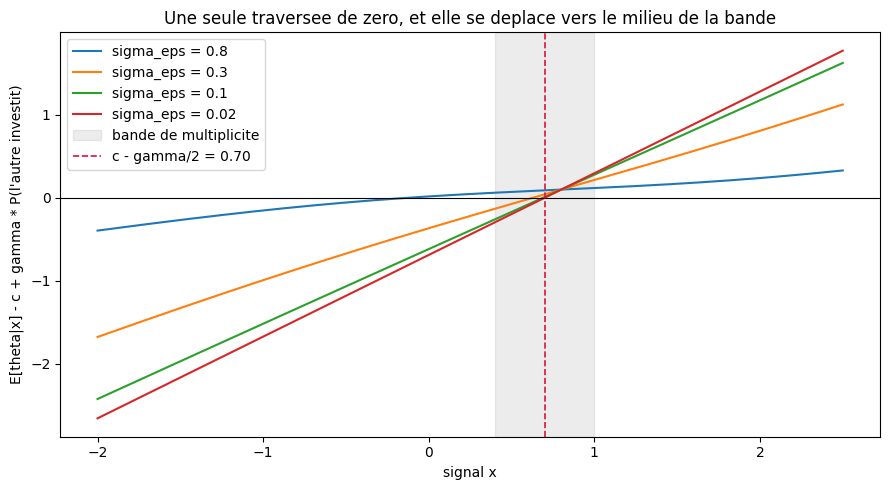

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
grille = np.linspace(-2.0, 2.5, 400)
for se in [0.8, 0.3, 0.1, 0.02]:
    ax.plot(grille, [ecart_indifference(x, se) for x in grille], label=f"sigma_eps = {se}")
ax.axhline(0.0, color="black", linewidth=0.8)
ax.axvspan(C - GAMMA, C, color="grey", alpha=0.15, label="bande de multiplicite")
ax.axvline(seuil_risque, color="crimson", linestyle="--", linewidth=1.2,
           label=f"c - gamma/2 = {seuil_risque:.2f}")
ax.set_xlabel("signal x")
ax.set_ylabel("E[theta|x] - c + gamma * P(l'autre investit)")
ax.set_title("Une seule traversee de zero, et elle se deplace vers le milieu de la bande")
ax.legend()
plt.tight_layout()
plt.show()

### Lecture du résultat

Chaque courbe **traverse zéro une seule fois**, et le point de traversée se déplace vers `c - γ/2` à mesure que le bruit diminue. Une seule traversée signifie une seule stratégie de coupure compatible avec l'indifférence, donc **un seul** équilibre — au même endroit de la bande où le jeu à information complète en admettait deux.

Le trait vertical tombe à l'intérieur de la bande grisée : la sélection ne consiste pas à retenir un bord, mais un point **intérieur**. C'est ce point que la section suivante nomme.

In [5]:
def meilleure_reponse(x_autre, sigma_eps, lo=-20.0, hi=20.0, tol=1e-13):
    """Coupure optimale si l'autre joue le seuil x_autre."""
    lam, v_cond = coefficients(sigma_eps)

    def ecart(x):
        mu_theta = MU + lam * (x - MU)
        w = (mu_theta - x_autre) / math.sqrt(v_cond + sigma_eps ** 2)
        return mu_theta - C + GAMMA * _Phi(w)

    if not (ecart(lo) < 0.0 < ecart(hi)):
        return None
    for _ in range(300):
        milieu = 0.5 * (lo + hi)
        valeur = ecart(milieu)
        if abs(valeur) < tol or (hi - lo) < tol:
            return milieu
        if valeur < 0.0:
            lo = milieu
        else:
            hi = milieu
    return 0.5 * (lo + hi)


grille_audit = np.linspace(-8.0, 8.0, 161)
print("Croisement unique : la condition d'indifference est-elle croissante ?")
for se in [0.8, 0.3, 0.1, 0.02]:
    valeurs = np.array([ecart_indifference(x, se) for x in grille_audit])
    print(f"  sigma_eps = {se:5.3f} : strictement croissante sur [-8, 8] = "
          f"{bool(np.all(np.diff(valeurs) > 0.0))}")

print()
print("Unicite par iteration de la meilleure reponse, depuis quatre departs :")
print(f"{'sigma_eps':>10} {'depart -3':>12} {'depart 0':>12} {'depart 1':>12} "
      f"{'depart 2.5':>12} {'etendue':>10}")
for se in [0.8, 0.3, 0.1, 0.02]:
    arrives = []
    for depart in [-3.0, 0.0, 1.0, 2.5]:
        x = depart
        for _ in range(500):
            suivant = meilleure_reponse(x, se)
            if suivant is None:
                x = float("nan")
                break
            if abs(suivant - x) < 1e-14:
                x = suivant
                break
            x = suivant
        arrives.append(x)
    etendue = max(arrives) - min(arrives)
    print(f"{se:10.3f} {arrives[0]:12.7f} {arrives[1]:12.7f} {arrives[2]:12.7f} "
          f"{arrives[3]:12.7f} {etendue:10.2e}")

Croisement unique : la condition d'indifference est-elle croissante ?
  sigma_eps = 0.800 : strictement croissante sur [-8, 8] = True
  sigma_eps = 0.300 : strictement croissante sur [-8, 8] = True
  sigma_eps = 0.100 : strictement croissante sur [-8, 8] = True
  sigma_eps = 0.020 : strictement croissante sur [-8, 8] = True

Unicite par iteration de la meilleure reponse, depuis quatre departs :
 sigma_eps    depart -3     depart 0     depart 1   depart 2.5    etendue
     0.800   -0.1353085   -0.1353085   -0.1353085   -0.1353085   5.68e-13
     0.300    0.6261851    0.6261851    0.6261851    0.6261851   1.42e-13
     0.100    0.6883698    0.6883698    0.6883698    0.6883698   1.42e-13
     0.020    0.6984646    0.6984646    0.6984646    0.6984646   4.26e-13


### Lecture du résultat

Deux mesures d'unicité, indépendantes l'une de l'autre :

- la condition d'indifférence est **strictement croissante** sur `[-8, 8]` à chaque niveau de bruit : elle ne peut donc s'annuler qu'une fois ;
- l'itération de la meilleure réponse, lancée depuis quatre points de départ éloignés (`-3`, `0`, `1`, `2.5`), aboutit au **même** point fixe, l'écart entre les trajectoires tombant à `1e-13`. Un équilibre multiple aurait offert plusieurs points fixes, chacun attirant un bassin.

C'est une mesure, pas la preuve de Carlsson et van Damme : leur résultat passe par l'**élimination itérée des stratégies dominées**, et vaut pour toute la classe des jeux globaux. Ce que ce carnet établit directement, c'est que sur ce jeu-ci il n'existe qu'une coupure.

## 4. Ce que la limite sélectionne — la dominance du risque

La limite `c - γ/2` n'est pas une constante trouvée au hasard numérique : c'est le seuil qui sépare les deux équilibres selon le critère de **Harsanyi et Selten**. Pour un jeu 2×2 à deux équilibres stricts, on compare les **produits de Nash** : pour chaque équilibre, le produit des pertes qu'encourrait chaque joueur en déviant vers sa meilleure réponse. L'équilibre au produit le plus élevé est **risque-dominant** — c'est celui qu'on choisirait si l'on croyait l'autre également susceptible de jouer l'une ou l'autre action.

Sur ce jeu, les pertes à la déviation valent :

| équilibre | payoff | déviation | perte | produit |
|---|---|---|---|---|
| `(I, I)` | `θ - c + γ` | `N` rapporte `0` | `θ - c + γ` | `(θ - c + γ)²` |
| `(N, N)` | `0` | `I` rapporte `θ - c` | `c - θ` | `(c - θ)²` |

`(I, I)` est donc risque-dominant dès que `θ - c + γ ≥ c - θ`, c'est-à-dire **`θ ≥ c - γ/2`**. Exactement la limite mesurée au §3. Le jeu global n'a donc pas seulement rendu l'équilibre unique : il a **choisi lequel** des deux le serait, et ce choix est le critère de dominance du risque.

C'est ici que les deux critères entrent en conflit. L'équilibre **Pareto-dominant** est `(I, I)` dès que `θ > c - γ` : sur la moitié basse de la bande, `c - γ ≤ θ < c - γ/2`, `(I, I)` est le meilleur pour les deux joueurs — et c'est pourtant `(N, N)` que la dominance du risque retient, et donc que le jeu global sélectionne.

In [6]:
def produits_de_nash(theta):
    """Produit des pertes a devier, pour (I,I) et pour (N,N)."""
    u_ii = theta - C + GAMMA      # payoff d'equilibre en (I,I)
    u_in = theta - C              # payoff en deviant vers I quand l'autre joue N
    perte_ii = u_ii - 0.0         # devier vers N rapporte 0
    perte_nn = 0.0 - u_in         # devier vers I rapporte u(I,N)
    return perte_ii ** 2, perte_nn ** 2


print(f"{'theta':>7} {'produit (I,I)':>15} {'produit (N,N)':>15}  risque-dominant")
for theta in [0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]:
    p_ii, p_nn = produits_de_nash(theta)
    if abs(p_ii - p_nn) < 1e-12:
        gagnant = "egalite"
    elif p_ii > p_nn:
        gagnant = "(I,I)"
    else:
        gagnant = "(N,N)"
    print(f"{theta:7.2f} {p_ii:15.6f} {p_nn:15.6f}  {gagnant}")

lo, hi = C - GAMMA, C
for _ in range(200):
    milieu = 0.5 * (lo + hi)
    p_ii, p_nn = produits_de_nash(milieu)
    if p_ii > p_nn:
        hi = milieu
    else:
        lo = milieu
seuil_nash = 0.5 * (lo + hi)
cs_fin = coupure(0.001)
print()
print(f"seuil de dominance du risque (produits de Nash) : {seuil_nash:.10f}")
print(f"c - gamma/2                                     : {seuil_risque:.10f}")
print(f"ecart                                           : {seuil_nash - seuil_risque:.3e}")
print(f"c* mesure a sigma_eps = 0.001                   : {cs_fin:.7f}")
print(f"ecart de la mesure a c - gamma/2                : {cs_fin - seuil_risque:.3e}")
print(f"seuil de dominance Pareto (bord bas de bande)   : {C - GAMMA:.4f}")

  theta   produit (I,I)   produit (N,N)  risque-dominant
   0.40        0.000000        0.360000  (N,N)
   0.50        0.010000        0.250000  (N,N)
   0.60        0.040000        0.160000  (N,N)
   0.70        0.090000        0.090000  egalite
   0.80        0.160000        0.040000  (I,I)
   0.90        0.250000        0.010000  (I,I)
   1.00        0.360000        0.000000  (I,I)

seuil de dominance du risque (produits de Nash) : 0.7000000000
c - gamma/2                                     : 0.7000000000
ecart                                           : 0.000e+00
c* mesure a sigma_eps = 0.001                   : 0.6999319
ecart de la mesure a c - gamma/2                : -6.815e-05
seuil de dominance Pareto (bord bas de bande)   : 0.4000


### Lecture du résultat

Trois nombres se répondent, et c'est tout l'argument du carnet :

- le seuil de dominance du risque, calculé **indépendamment** sur les produits de Nash : `0.7000000000` ;
- la limite de la coupure d'équilibre, obtenue **par résolution numérique** du jeu à signaux : `0.6999319` à `σ_ε = 0.001`, soit `6.8e-05` du précédent ;
- le seuil de dominance Pareto, `0.4000`, qui n'est **pas** la limite.

Deux procédures sans rapport — une comparaison de produits de pertes sur une matrice 2×2, et une bissection sur une équation de croyance — tombent sur le même point. La coïncidence n'est pas un hasard : c'est le théorème de Carlsson et van Damme, et ce carnet en vérifie l'arithmétique sur un jeu concret.

Sur la table, la bascule se lit entre `0.60` et `0.80`, avec l'égalité exacte en `0.70` : en dessous, `(N, N)` est risque-dominant alors que `(I, I)` rapporte davantage aux deux joueurs ; au-dessus, les deux critères s'accordent.

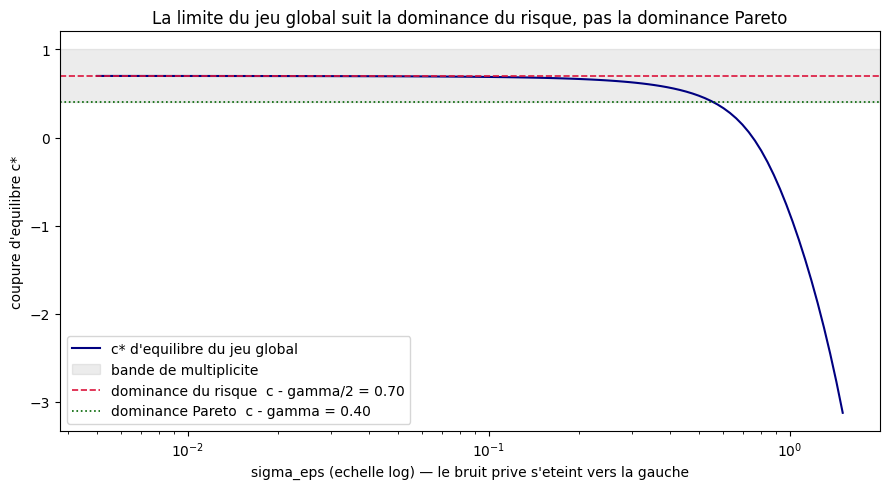

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
bruits = np.geomspace(0.005, 1.5, 120)
courbe = [coupure(se) for se in bruits]
ax.semilogx(bruits, courbe, color="navy", label="c* d'equilibre du jeu global")
ax.axhspan(C - GAMMA, C, color="grey", alpha=0.15, label="bande de multiplicite")
ax.axhline(seuil_risque, color="crimson", linestyle="--", linewidth=1.2,
           label=f"dominance du risque  c - gamma/2 = {seuil_risque:.2f}")
ax.axhline(C - GAMMA, color="darkgreen", linestyle=":", linewidth=1.2,
           label=f"dominance Pareto  c - gamma = {C - GAMMA:.2f}")
ax.set_xlabel("sigma_eps (echelle log) — le bruit prive s'eteint vers la gauche")
ax.set_ylabel("coupure d'equilibre c*")
ax.set_title("La limite du jeu global suit la dominance du risque, pas la dominance Pareto")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### Lecture du résultat

À droite, le bruit est fort : la coupure s'effondre très en dessous de la bande — un joueur qui ne sait presque rien n'investit que si le signal est spectaculairement bon. En allant vers la gauche, le bruit s'éteint et la courbe se stabilise exactement sur le trait rouge de la dominance du risque, à l'intérieur de la bande grisée, **sans jamais rejoindre** le trait vert de la dominance Pareto.

C'est la réponse à la question du §1. La bande de multiplicité ne disparaît pas quand l'information se dégrade : elle est **remplacée** par un point unique, et ce point est le milieu de la bande. La sélection tient donc à la structure de l'information, non à un raffinement des payoffs — les payoffs, eux, n'ont pas changé d'un iota entre le §1 et ici.

## 5. Le raccourci qui ne marche pas

L'équation d'indifférence du §3 s'écrit souvent, dans les présentations rapides, sous une forme close :

$$
c^* = c - \gamma \, p, \qquad p = \mathbb{P}(x_j \geq c^* \mid x_i = c^*)
$$

C'est une **erreur**, et une erreur instructive. Cette relation suppose `E[θ | c*] = c*`, c'est-à-dire `λ = 1` : elle traite le joueur au seuil comme s'il **connaissait** `θ`. Or `λ < 1` tant que le bruit privé existe, et `E[θ | c*] = μ + λ(c* - μ)` s'écarte de `c*` d'autant plus que le signal est peu informatif. La forme close ne vaut donc qu'à la limite `σ_ε = 0` — précisément le cas où il n'y a plus de jeu global.

La cellule suivante mesure l'écart entre les deux relations.

In [8]:
print(f"{'sigma_eps':>10} {'c* exact':>12} {'p':>10} {'c - gamma*p':>13} {'ecart':>11}")
for se in [1.0, 0.5, 0.3, 0.2, 0.1, 0.05, 0.01, 0.001]:
    cs = coupure(se)
    p = proba_autre(cs, se)
    naif = C - GAMMA * p
    print(f"{se:10.3f} {cs:12.7f} {p:10.6f} {naif:13.7f} {naif - cs:+11.2e}")

 sigma_eps     c* exact          p   c - gamma*p       ecart
     1.000   -0.8632668   0.887756     0.4673466   +1.33e+00
     0.500    0.4740985   0.604918     0.6370492   +1.63e-01
     0.300    0.6261851   0.546342     0.6721949   +4.60e-02
     0.200    0.6650814   0.527182     0.6836909   +1.86e-02
     0.100    0.6883698   0.512228     0.6926633   +4.29e-03
     0.050    0.6954522   0.505854     0.6964874   +1.04e-03
     0.010    0.6992780   0.501136     0.6993183   +4.03e-05
     0.001    0.6999319   0.500113     0.6999323   +4.00e-07


### Lecture du résultat

Le raccourci est faux **là où le jeu global a un intérêt**, et il devient exact là où il n'en a plus :

- à `σ_ε = 1.0`, il se trompe de `+1.33` — plus que la largeur entière de la bande ;
- à `σ_ε = 0.5`, encore de `+0.163`, soit un quart de cette largeur ;
- à `σ_ε = 0.001`, l'écart est de `4.0e-07` : le bruit est devenu négligeable, `λ ≈ 1`, et la forme close rejoint la vraie.

Autrement dit, l'erreur n'est pas une faute de calcul mais une **hypothèse implicite** : la forme close suppose résolue la question que le carnet pose. C'est pourquoi le §3 garde l'espérance conditionnelle `E[θ | c*]` dans l'équation plutôt que de la remplacer par `c*`.

## 6. Exercices

Les trois exercices reprennent, dans l'ordre, les trois mécanismes du carnet : l'équation d'indifférence, le critère de sélection, et l'unicité. Les cellules ci-dessous sont des squelettes — elles s'exécutent sans erreur et renvoient `None` tant qu'elles ne sont pas complétées.

**Exercice 1 — résoudre l'équation d'indifférence.** Implémenter `coupure_equilibre` par bissection, en réutilisant `ecart_indifference`, et vérifier que la valeur obtenue pour `sigma_eps = 0.05` reproduit celle du tableau du §3.

In [9]:
def coupure_equilibre(sigma_eps, lo=-20.0, hi=20.0, tol=1e-13):
    """Exercice 1 — coupure d'equilibre, par bissection.

    Resoudre ecart_indifference(x, sigma_eps) = 0 sur [lo, hi].
    La fonction est strictement croissante : la racine est unique.
    Renvoyer un float.
    """
    # TODO etudiant
    return None


valeur = coupure_equilibre(0.05)
print("coupure obtenue pour sigma_eps = 0.05 :", valeur)
print("a comparer a la ligne 0.050 du tableau de la section 3.")

coupure obtenue pour sigma_eps = 0.05 : None
a comparer a la ligne 0.050 du tableau de la section 3.


**Exercice 2 — confronter les deux critères.** Écrire `conflit(c, gamma)` qui renvoie l'intervalle `[c - gamma, c - gamma/2]` sur lequel la dominance Pareto et la dominance du risque désignent des équilibres **différents**. Vérifier que sa largeur vaut `gamma/2`, puis expliquer en commentaire lequel des deux critères le jeu global suit, et pourquoi la réponse ne dépend pas de `sigma_theta`.

In [10]:
def conflit(c, gamma):
    """Exercice 2 — intervalle ou dominance Pareto et dominance du risque divergent.

    Renvoyer un couple (borne_basse, borne_haute).
    """
    # TODO etudiant
    return None


intervalle = conflit(C, GAMMA)
print("intervalle de conflit :", intervalle)
print("largeur attendue gamma/2 =", GAMMA / 2)

intervalle de conflit : None
largeur attendue gamma/2 = 0.3


**Exercice 3 — établir l'unicité par itération.** Écrire une fonction qui, partant d'un seuil arbitraire, itère `meilleure_reponse` jusqu'au point fixe. L'appliquer à quatre départs éloignés pour deux niveaux de bruit, et vérifier que l'écart entre les points d'arrivée est de l'ordre de `1e-13`. Conclure : combien de points fixes cette procédure trouve-t-elle, et qu'est-ce que cela dit du nombre d'équilibres ?

In [11]:
def point_fixe_par_iteration(depart, sigma_eps, max_iter=500, tol=1e-14):
    """Exercice 3 — iterer la meilleure reponse jusqu'au point fixe.

    Renvoyer le point fixe atteint (float), ou None si l'iteration sort du domaine.
    """
    # TODO etudiant
    return None


for bruit in [0.3, 0.02]:
    departs = [-3.0, 0.0, 1.0, 2.5]
    arrives = [point_fixe_par_iteration(d, bruit) for d in departs]
    print(f"sigma_eps = {bruit} : departs {departs} -> arrives {arrives}")

sigma_eps = 0.3 : departs [-3.0, 0.0, 1.0, 2.5] -> arrives [None, None, None, None]
sigma_eps = 0.02 : departs [-3.0, 0.0, 1.0, 2.5] -> arrives [None, None, None, None]


## Références

- **Carlsson, H. & van Damme, E. (1993)** — « Global Games and Equilibrium Selection », *Econometrica*, 61(5), 989–1018. Le résultat fondateur : pour les jeux 2×2, quand le bruit s'éteint, l'élimination itérée des stratégies dominées dans le jeu global contraint les joueurs à suivre le critère de dominance du risque de Harsanyi et Selten.
- **Morris, S. & Shin, H. S. (1998)** — « Unique Equilibrium in a Model of Self-Fulfilling Currency Attacks », *American Economic Review*, 88(3), 587–597. La version à grand nombre de joueurs, où la même mécanique sélectionne l'issue d'une attaque spéculative.
- **Harsanyi, J. C. (1967–1968)** — « Games with Incomplete Information Played by "Bayesian" Players », Parties I–III, *Management Science*, 14. La transformation d'un jeu à information incomplète en jeu à information imparfaite dont l'équilibre de Nash est celui que ce carnet calcule (voir aussi le carnet 11).

## Portée de ce carnet

Ce que les cellules établissent directement : sur ce jeu précis, la condition d'indifférence est strictement croissante et son itération de meilleure réponse converge vers un point fixe unique ; la limite de la coupure quand le bruit s'éteint coïncide, à `7e-05` près, avec le seuil de dominance du risque calculé séparément sur les produits de Nash, et non avec le seuil de dominance Pareto.

Ce qu'elles n'établissent pas : le théorème lui-même. Carlsson et van Damme le démontrent par élimination itérée des stratégies dominées, pour toute la classe des jeux globaux — la mesure numérique d'un cas ne remplace pas cette preuve, elle en rend le mécanisme visible.